### Integralrechnung: Stammfunktionen, Flächen, Rekonstruktion, Rotationskörper - Übungen

In diesem Notebook geht es um die **Integralrechnung**: Stammfunktionen, das bestimmte Integral, Flächen unter und zwischen Graphen,
die Rekonstruktion eines Bestands aus seiner Änderungsrate und (im Leistungsfach) Rotationskörper und uneigentliche Integrale.

sympy integriert mit `integrate()`. Bestimme Stammfunktionen trotzdem zuerst **von Hand** und prüfe sie mit `diff()` oder `integrate()`.
Beim Flächenberechnen ist die wichtigste Arbeit deine: Nullstellen finden, Intervalle richtig aufteilen, Vorzeichen beachten.

Vorausgesetzt werden die Notebooks *Ableitungsregeln* und *Funktionsanalyse*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die reellen Variablen `x`, `t` und die Parameter `a`, `b`, `k` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, t = symbols('x t', real=True)
a, b, k = symbols('a b k', real=True)

## 1. Stammfunktionen

#### F' = f

Eine Funktion F heißt **Stammfunktion** von f, wenn F'(x) = f(x). Mit F ist auch F + C eine Stammfunktion (C eine Konstante).

`integrate(f, x)` gibt **eine** Stammfunktion aus, **ohne** + C. Prüfen kannst du jede Stammfunktion durch Ableiten.

| f(x) | F(x) |
|---|---|
| xⁿ (n ≠ −1) | xⁿ⁺¹ / (n + 1) |
| e^(kx) | e^(kx) / k |
| sin(kx) | −cos(kx) / k |
| cos(kx) | sin(kx) / k |
| 1/x (Leistungsfach) | ln\|x\| (sympy schreibt nur `log(x)`, gemeint ist für x < 0 ln(−x)) |

Für eine **lineare Verkettung** f(ax + b) gilt: F(ax + b) / a.

In [ ]:
display(integrate(x**3, x))
display(integrate(exp(2*x), x))
display(integrate(sin(x) + 4, x))
display(integrate((2*x + 1)**3, x))
F = x**4 / 4 + 7
diff(F, x)

#### Aufgabe 1.1

Gib eine Stammfunktion von f(x) = 6x² − 4x + 1 aus.

**Erwartete Ausgabe:**

$\displaystyle 2 x^{3} - 2 x^{2} + x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(6*x**2 - 4*x + 1, x)
```

</details>

#### Aufgabe 1.2

Gib eine Stammfunktion von f(x) = 1/x² aus.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(1 / x**2, x)
```

</details>

#### Aufgabe 1.3

Gib eine Stammfunktion von f(x) = √x aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{2 x^{\frac{3}{2}}}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(sqrt(x), x)
```

</details>

#### Aufgabe 1.4

Gib eine Stammfunktion von f(x) = 3 · e^(−x) aus.

**Erwartete Ausgabe:**

$\displaystyle - 3 e^{- x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(3 * exp(-x), x)
```

</details>

#### Aufgabe 1.5

Gib eine Stammfunktion von f(x) = cos(2x) − sin(x) aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{\sin{\left(2 x \right)}}{2} + \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(cos(2*x) - sin(x), x)
```

</details>

#### Aufgabe 1.6

Gib eine Stammfunktion von f(x) = (3x − 1)⁵ aus (sympy multipliziert aus). Berechne dann mit `simplify` die Differenz zur Stammfunktion (3x − 1)⁶/18,
die man mit der Regel für lineare Verkettungen erhält. Ist die Differenz eine Konstante, sind beide Stammfunktionen.

**Erwartete Ausgabe:**

$\displaystyle \frac{81 x^{6}}{2} - 81 x^{5} + \frac{135 x^{4}}{2} - 30 x^{3} + \frac{15 x^{2}}{2} - x$

$\displaystyle - \frac{1}{18}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = integrate((3*x - 1)**5, x)
display(F)
simplify(F - (3*x - 1)**6 / 18)
```

</details>

#### Aufgabe 1.7

Gib eine Stammfunktion von f(x) = e^(kx) aus (k ≠ 0, lege dafür ein Symbol `k` mit `nonzero=True` an).

**Erwartete Ausgabe:**

$\displaystyle \frac{e^{k x}}{k}$

In [ ]:
k = symbols('k', real=True, nonzero=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k', real=True, nonzero=True)
integrate(exp(k*x), x)
```

</details>

#### Aufgabe 1.8

Gib eine Stammfunktion von f(x) = 2/x aus. **(Leistungsfach)**

**Erwartete Ausgabe:**

$\displaystyle 2 \log{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(2 / x, x)
```

</details>

#### Aufgabe 1.9

Prüfe, ob F(x) = x · eˣ − eˣ eine Stammfunktion von f(x) = x · eˣ ist (`simplify(F' − f)`).

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = x * exp(x) - exp(x)
simplify(diff(F, x) - x * exp(x))
```

</details>

#### Aufgabe 1.10

Prüfe, ob F(x) = (x² + 1)³ eine Stammfunktion von f(x) = 6x · (x² + 1)² ist.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = (x**2 + 1)**3
simplify(diff(F, x) - 6*x * (x**2 + 1)**2)
```

</details>

#### Aufgabe 1.11

Bestimme die Stammfunktion von f(x) = 2x − 3, deren Graph durch P(1 | 4) geht: Setze F(x) = (Stammfunktion) + C an und bestimme C.

**Erwartete Ausgabe:**

$\displaystyle x^{2} - 3 x + 6$

In [ ]:
C = symbols('C')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
C = symbols('C')
F = integrate(2*x - 3, x) + C
F.subs(C, solve(Eq(F.subs(x, 1), 4), C)[0])
```

</details>

#### Aufgabe 1.12

Bestimme die Stammfunktion von f(x) = eˣ + 1, deren Graph durch den Ursprung geht.

**Erwartete Ausgabe:**

$\displaystyle x + e^{x} - 1$

In [ ]:
C = symbols('C')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
C = symbols('C')
F = integrate(exp(x) + 1, x) + C
F.subs(C, solve(Eq(F.subs(x, 0), 0), C)[0])
```

</details>

#### Aufgabe 1.13

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(integrate(1, x))
display(integrate(x, x))
display(integrate(exp(x), x))
simplify(diff(integrate(sin(x)**3, x), x) - sin(x)**3)
```

In [ ]:
display(integrate(1, x))
display(integrate(x, x))
display(integrate(exp(x), x))
simplify(diff(integrate(sin(x)**3, x), x) - sin(x)**3)

## 2. Das bestimmte Integral und der Hauptsatz

#### ∫ₐᵇ f(x) dx = F(b) − F(a)

Das **bestimmte Integral** von a bis b ist der **orientierte Flächeninhalt**: Flächen oberhalb der x-Achse zählen positiv,
Flächen unterhalb negativ. Nach dem **Hauptsatz der Differential- und Integralrechnung** berechnet man es mit einer
beliebigen Stammfunktion F: ∫ₐᵇ f(x) dx = F(b) − F(a).

In sympy: `integrate(f, (x, a, b))`. Mit `Integral(f, (x, a, b))` wird das Integral nur **hingeschrieben**; `.doit()` rechnet es aus.

In [ ]:
I = Integral(x**2, (x, 0, 3))
display(Eq(I, I.doit()))
F = integrate(x**2, x)
display(F.subs(x, 3) - F.subs(x, 0))
display(integrate(x**3 - 4*x, (x, 0, 2)))
plot(x**2, (x, 0, 3));

#### Aufgabe 2.1

Berechne ∫₁⁴ (2x + 1) dx einmal mit F(4) − F(1) und einmal mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle 18$

$\displaystyle 18$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = integrate(2*x + 1, x)
display(F.subs(x, 4) - F.subs(x, 1))
integrate(2*x + 1, (x, 1, 4))
```

</details>

#### Aufgabe 2.2

Berechne ∫₀² (x³ − x) dx.

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(x**3 - x, (x, 0, 2))
```

</details>

#### Aufgabe 2.3

Berechne ∫₀^π sin(x) dx und ∫₀^(2π) sin(x) dx.

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(integrate(sin(x), (x, 0, pi)))
integrate(sin(x), (x, 0, 2*pi))
```

</details>

#### Aufgabe 2.4

Berechne ∫₀¹ eˣ dx genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle -1 + e$

$\displaystyle 1.718$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I = integrate(exp(x), (x, 0, 1))
display(I)
N(I, 4)
```

</details>

#### Aufgabe 2.5

Berechne ∫₁^e (1/x) dx. **(Leistungsfach)**

**Erwartete Ausgabe:**

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(1 / x, (x, 1, E))
```

</details>

#### Aufgabe 2.6

Gib die Gleichung ∫₋₁² x² dx = (Wert) mit `Eq(Integral(...), ...)` aus wie im Beispiel.

**Erwartete Ausgabe:**

$\displaystyle \int\limits_{-1}^{2} x^{2}\, dx = 3$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I = Integral(x**2, (x, -1, 2))
Eq(I, I.doit())
```

</details>

#### Aufgabe 2.7

Berechne ∫₀ᵇ (2x) dx allgemein und bestimme b > 0 so, dass das Integral 9 ist.

**Erwartete Ausgabe:**

$\displaystyle b^{2}$

$\displaystyle \left[ 3\right]$

In [ ]:
b = symbols('b', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
b = symbols('b', positive=True)
I = integrate(2*x, (x, 0, b))
display(I)
solve(Eq(I, 9), b)
```

</details>

#### Aufgabe 2.8

Für welches a > 0 gilt ∫₀ᵃ (x² − 2x) dx = 0?

**Erwartete Ausgabe:**

$\displaystyle \left[ 3\right]$

In [ ]:
a = symbols('a', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', positive=True)
solve(integrate(x**2 - 2*x, (x, 0, a)), a)
```

</details>

#### Aufgabe 2.9

Prüfe die Regel ∫ₐᵇ f + ∫ᵇᶜ f = ∫ₐᶜ f für f(x) = x² mit a = 0, b = 1, c = 3.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2
integrate(f, (x, 0, 1)) + integrate(f, (x, 1, 3)) == integrate(f, (x, 0, 3))
```

</details>

#### Aufgabe 2.10

Prüfe die Regel ∫ₐᵇ f = −∫ᵇᵃ f für f(x) = eˣ mit a = 0, b = 2.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(exp(x), (x, 0, 2)) == -integrate(exp(x), (x, 2, 0))
```

</details>

#### Aufgabe 2.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(integrate(x, (x, -1, 1)))
display(integrate(x**2, (x, -1, 1)))
display(integrate(5, (x, 2, 2)))
integrate(1, (x, 0, 7))
```

In [ ]:
display(integrate(x, (x, -1, 1)))
display(integrate(x**2, (x, -1, 1)))
display(integrate(5, (x, 2, 2)))
integrate(1, (x, 0, 7))

## 3. Flächen zwischen Graph und x-Achse

#### Erst die Nullstellen, dann integrieren

Das Integral rechnet Flächen unter der x-Achse negativ. Für den **Flächeninhalt** teilt man das Intervall an den Nullstellen auf
und addiert die **Beträge** der Teilintegrale (`Abs()`).

Beispiel: f(x) = x³ − 4x hat die Nullstellen −2, 0, 2. Das Integral von −2 bis 2 ist 0, der Flächeninhalt aber 8.

In [ ]:
f = x**3 - 4*x
display(solve(f, x))
display(integrate(f, (x, -2, 2)))
A = Abs(integrate(f, (x, -2, 0))) + Abs(integrate(f, (x, 0, 2)))
display(A)
plot(f, (x, -2.5, 2.5));

#### Aufgabe 3.1

Berechne den Flächeninhalt zwischen dem Graphen von f(x) = −x² + 4 und der x-Achse.

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  2\right]$

$\displaystyle \frac{32}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = -x**2 + 4
ns = solve(f, x)
display(ns)
integrate(f, (x, ns[0], ns[1]))
```

</details>

#### Aufgabe 3.2

Berechne den Flächeninhalt, den f(x) = x² − 2x mit der x-Achse einschließt.

**Erwartete Ausgabe:**

$\displaystyle \frac{4}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2 - 2*x
ns = solve(f, x)
Abs(integrate(f, (x, ns[0], ns[1])))
```

</details>

#### Aufgabe 3.3

Berechne den Flächeninhalt zwischen dem Graphen von f(x) = x³ − x und der x-Achse (zwei Teilflächen).

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  0, \  1\right]$

$\displaystyle \frac{1}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - x
display(solve(f, x))
Abs(integrate(f, (x, -1, 0))) + Abs(integrate(f, (x, 0, 1)))
```

</details>

#### Aufgabe 3.4

Berechne den Flächeninhalt zwischen dem Graphen von f(x) = sin(x) und der x-Achse über [0, 2π].

**Erwartete Ausgabe:**

$\displaystyle 4$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Abs(integrate(sin(x), (x, 0, pi))) + Abs(integrate(sin(x), (x, pi, 2*pi)))
```

</details>

#### Aufgabe 3.5

Berechne den Flächeninhalt zwischen f(x) = x² − 1 und der x-Achse über dem Intervall [0, 2] (Nullstelle bei 1 beachten).

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2 - 1
Abs(integrate(f, (x, 0, 1))) + Abs(integrate(f, (x, 1, 2)))
```

</details>

#### Aufgabe 3.6

Berechne für f(x) = x · e⁻ˣ den Flächeninhalt zwischen Graph und x-Achse über [0, 3] genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 1 - \frac{4}{e^{3}}$

$\displaystyle 0.8008$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A = integrate(x * exp(-x), (x, 0, 3))
display(A)
N(A, 4)
```

</details>

#### Aufgabe 3.7

Schreibe eine Funktion `flaeche(f, a, b)`, die die Nullstellen von f im Intervall (a, b) mit `solveset(f, x, Interval.open(a, b))` sucht,
das Intervall dort aufteilt und die Beträge der Teilintegrale addiert. Teste mit f(x) = x³ − 4x auf [−2, 2] und mit f(x) = sin(x) auf [0, 2π].

**Erwartete Ausgabe:**

$\displaystyle 8$

$\displaystyle 4$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def flaeche(f, a, b):
    stellen = [a] + sorted(solveset(f, x, Interval.open(a, b))) + [b]
    A = 0
    for i in range(len(stellen) - 1):
        A = A + Abs(integrate(f, (x, stellen[i], stellen[i + 1])))
    return A

display(flaeche(x**3 - 4*x, -2, 2))
flaeche(sin(x), 0, 2*pi)
```

</details>

#### Aufgabe 3.8

Für welches k > 0 schließt der Graph von f(x) = −x² + k mit der x-Achse den Flächeninhalt 36 ein?

**Erwartete Ausgabe:**

$\displaystyle \left[ 9\right]$

In [ ]:
k = symbols('k', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k', positive=True)
f = -x**2 + k
ns = solve(f, x)
solve(Eq(integrate(f, (x, ns[0], ns[1])), 36), k)
```

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
f = x**2 - 4
display(integrate(f, (x, -2, 2)))
display(Abs(integrate(f, (x, -2, 2))))
integrate(Abs(f), (x, -2, 2))
```

In [ ]:
f = x**2 - 4
display(integrate(f, (x, -2, 2)))
display(Abs(integrate(f, (x, -2, 2))))
integrate(Abs(f), (x, -2, 2))

## 4. Flächen zwischen zwei Graphen

#### ∫ (f − g)

Der Flächeninhalt zwischen den Graphen von f und g über [a, b] ist ∫ₐᵇ (f(x) − g(x)) dx, wenn f ≥ g ist.
Die Grenzen sind oft die **Schnittstellen** (f(x) = g(x)). Schneiden sich die Graphen dazwischen, teilt man auf und nimmt Beträge.

In [ ]:
f = -x**2 + 4
g = x + 2
s = solve(Eq(f, g), x)
display(s)
display(integrate(f - g, (x, s[0], s[1])))
plot(f, g, (x, -3, 2));

#### Aufgabe 4.1

Berechne den Flächeninhalt zwischen f(x) = x² und g(x) = x.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  1\right]$

$\displaystyle \frac{1}{6}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s = solve(Eq(x**2, x), x)
display(s)
Abs(integrate(x**2 - x, (x, s[0], s[1])))
```

</details>

#### Aufgabe 4.2

Berechne den Flächeninhalt zwischen f(x) = 4 − x² und g(x) = x² − 4.

**Erwartete Ausgabe:**

$\displaystyle \frac{64}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
s = solve(Eq(4 - x**2, x**2 - 4), x)
integrate((4 - x**2) - (x**2 - 4), (x, s[0], s[1]))
```

</details>

#### Aufgabe 4.3

Berechne den Flächeninhalt zwischen f(x) = x³ und g(x) = x (zwei Teilflächen).

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  0, \  1\right]$

$\displaystyle \frac{1}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve(Eq(x**3, x), x))
Abs(integrate(x**3 - x, (x, -1, 0))) + Abs(integrate(x**3 - x, (x, 0, 1)))
```

</details>

#### Aufgabe 4.4

Berechne den Flächeninhalt zwischen f(x) = eˣ, g(x) = 1 − x und der Geraden x = 1 (Schnittstelle bei 0) genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle - \frac{3}{2} + e$

$\displaystyle 1.218$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A = integrate(exp(x) - (1 - x), (x, 0, 1))
display(A)
N(A, 4)
```

</details>

#### Aufgabe 4.5

Berechne den Flächeninhalt zwischen f(x) = sin(x) und g(x) = cos(x) über [π/4, 5π/4] (dort ist sin ≥ cos).

**Erwartete Ausgabe:**

$\displaystyle 2 \sqrt{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(sin(x) - cos(x), (x, pi/4, 5*pi/4))
```

</details>

#### Aufgabe 4.6

Zeichne f(x) = x² und g(x) = 2x + 3 und berechne den Flächeninhalt zwischen ihnen.

**Erwartete Ausgabe:**

$\displaystyle \frac{32}{3}$

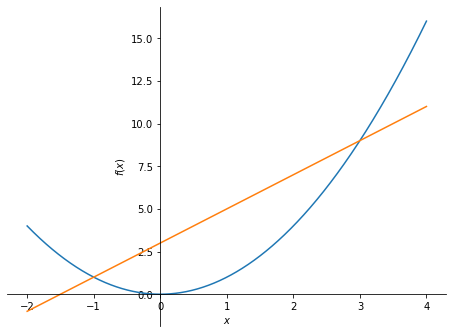

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f, g = x**2, 2*x + 3
plot(f, g, (x, -2, 4));
s = solve(Eq(f, g), x)
integrate(g - f, (x, s[0], s[1]))
```

</details>

#### Aufgabe 4.7

Die Gerade y = c teilt die Fläche zwischen f(x) = −x² + 4 und der x-Achse (Inhalt 32/3) in zwei gleich große Teile.
Bestimme c mit `nsolve` (Startwert 1): Die Fläche oberhalb von y = c reicht von −√(4 − c) bis √(4 − c) und soll 16/3 sein.

**Erwartete Ausgabe:**

$\displaystyle 1.48$

In [ ]:
c = symbols('c', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c = symbols('c', positive=True)
w = sqrt(4 - c)
A_oben = integrate(-x**2 + 4 - c, (x, -w, w))
N(nsolve(A_oben - Rational(16, 3), c, 1), 4)
```

</details>

## 5. Integralfunktion und Bestand aus Änderungsrate

#### Iₐ(x) = ∫ₐˣ f(t) dt

Hält man die untere Grenze fest und lässt die obere Grenze variabel, erhält man die **Integralfunktion** Iₐ(x) = ∫ₐˣ f(t) dt.
Sie ist eine Stammfunktion von f mit Iₐ(a) = 0. Die Integrationsvariable heißt dann t, damit sie sich von der Grenze x unterscheidet.

**Rekonstruktion:** Ist f die **Änderungsrate** einer Größe (z. B. Zuflussrate in Liter pro Minute), dann ist ∫ₐᵇ f(t) dt die
**Änderung des Bestands** von a bis b. Bestand am Ende = Anfangsbestand + Integral.

In [ ]:
I = integrate(t**2 - 1, (t, 0, x))
display(I)
display(diff(I, x))
r = 20 - 2*t
display(integrate(r, (t, 0, 5)))
100 + integrate(r, (t, 0, 5))

#### Aufgabe 5.1

Gib die Integralfunktion I₀(x) = ∫₀ˣ (2t + 3) dt aus und prüfe, dass I₀(0) = 0.

**Erwartete Ausgabe:**

$\displaystyle x^{2} + 3 x$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I = integrate(2*t + 3, (t, 0, x))
display(I)
I.subs(x, 0)
```

</details>

#### Aufgabe 5.2

Gib die Integralfunktion I₁(x) = ∫₁ˣ 3t² dt aus.

**Erwartete Ausgabe:**

$\displaystyle x^{3} - 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(3*t**2, (t, 1, x))
```

</details>

#### Aufgabe 5.3

Gib die Integralfunktion I₀(x) = ∫₀ˣ cos(t) dt aus und ihre Ableitung.

**Erwartete Ausgabe:**

$\displaystyle \sin{\left(x \right)}$

$\displaystyle \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I = integrate(cos(t), (t, 0, x))
display(I)
diff(I, x)
```

</details>

#### Aufgabe 5.4

Bestimme die Nullstellen der Integralfunktion I₀(x) = ∫₀ˣ (t² − 4) dt.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  - 2 \sqrt{3}, \  2 \sqrt{3}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(integrate(t**2 - 4, (t, 0, x)), x)
```

</details>

#### Aufgabe 5.5

**Wassertank:** In einen Tank mit 200 Litern fließt Wasser mit der Rate r(t) = 30 − 3t (Liter pro Minute, t in Minuten). Wie viel Wasser fließt in den ersten
10 Minuten zu? Wie viel ist dann im Tank?

**Erwartete Ausgabe:**

$\displaystyle 150$

$\displaystyle 350$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r = 30 - 3*t
zu = integrate(r, (t, 0, 10))
display(zu)
200 + zu
```

</details>

#### Aufgabe 5.6

Wie die vorige Aufgabe: Ab t = 10 ist die Rate negativ (Wasser fließt ab). Gib die Bestandsfunktion B(x) = 200 + ∫₀ˣ r(t) dt aus und den Zeitpunkt, zu dem der Tank leer ist.

**Erwartete Ausgabe:**

$\displaystyle - \frac{3 xp^{2}}{2} + 30 xp + 200$

$\displaystyle \left[ 10 + \frac{10 \sqrt{21}}{3}\right]$

In [ ]:
xp = symbols('xp', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
xp = symbols('xp', positive=True)
r = 30 - 3*t
B = 200 + integrate(r, (t, 0, xp))
display(expand(B))
solve(B, xp)
```

</details>

#### Aufgabe 5.7

**Fahrt:** Ein Auto bremst mit der Geschwindigkeit v(t) = 20 − 4t (in m/s). Wann steht es? Welche Strecke legt es bis dahin zurück?

**Erwartete Ausgabe:**

$\displaystyle 5$

$\displaystyle 50$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
v = 20 - 4*t
ts = solve(v, t)[0]
display(ts)
integrate(v, (t, 0, ts))
```

</details>

#### Aufgabe 5.8

**Bevölkerung:** Eine Stadt wächst mit der Rate w(t) = 500 · e^(0,02t) Einwohner pro Jahr (0,02 als `Rational`). Um wie viele Einwohner wächst sie
in den ersten 10 Jahren (genau und gerundet auf eine ganze Zahl mit `round(N(...))`)?

**Erwartete Ausgabe:**

$\displaystyle -25000 + 25000 e^{\frac{1}{5}}$

$\displaystyle 5535$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = 500 * exp(Rational(2, 100) * t)
zuwachs = integrate(w, (t, 0, 10))
display(zuwachs)
round(N(zuwachs))
```

</details>

## 6. Mittelwert einer Funktion

#### m = 1/(b − a) · ∫ₐᵇ f(x) dx

Der **Mittelwert** einer Funktion auf [a, b] ist die Höhe des Rechtecks über [a, b], das denselben (orientierten) Flächeninhalt hat wie die Fläche unter dem Graphen.

In [ ]:
f = x**2
m = integrate(f, (x, 0, 3)) / 3
display(m)
plot(f, m, (x, 0, 3));

#### Aufgabe 6.1

Berechne den Mittelwert von f(x) = x³ auf [0, 2].

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(x**3, (x, 0, 2)) / 2
```

</details>

#### Aufgabe 6.2

Berechne den Mittelwert von f(x) = sin(x) auf [0, π] genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \frac{2}{\pi}$

$\displaystyle 0.6366$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = integrate(sin(x), (x, 0, pi)) / pi
display(m)
N(m, 4)
```

</details>

#### Aufgabe 6.3

**Temperatur:** Die Temperatur an einem Tag ist T(t) = 6 · sin(π/12 · (t − 9)) + 14 (°C, t in Stunden). Berechne die mittlere Temperatur zwischen 6 und 18 Uhr (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 16.7$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = 6 * sin(pi / 12 * (t - 9)) + 14
N(integrate(T, (t, 6, 18)) / 12, 4)
```

</details>

#### Aufgabe 6.4

An welcher Stelle in [0, 3] nimmt f(x) = x² seinen Mittelwert auf [0, 3] an?

**Erwartete Ausgabe:**

$\displaystyle \left[ \sqrt{3}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = integrate(x**2, (x, 0, 3)) / 3
[w for w in solve(Eq(x**2, m), x) if 0 <= w <= 3]
```

</details>

## 7. Rotationskörper (Leistungsfach)

#### V = π · ∫ₐᵇ f(x)² dx

Dreht sich der Graph von f über [a, b] um die x-Achse, entsteht ein **Rotationskörper**. Sein Volumen ist V = π · ∫ₐᵇ f(x)² dx
(viele dünne Zylinderscheiben mit Radius f(x)).

In [ ]:
f = sqrt(x)
V = pi * integrate(f**2, (x, 0, 4))
display(V)
N(V, 4)

#### Aufgabe 7.1

Ein Kegel entsteht, wenn f(x) = x/2 über [0, 6] um die x-Achse rotiert. Berechne das Volumen und vergleiche mit der Kegelformel V = π r² h / 3.

**Erwartete Ausgabe:**

$\displaystyle 18 \pi$

$\displaystyle 18 \pi$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
V = pi * integrate((x / 2)**2, (x, 0, 6))
display(V)
pi * 3**2 * 6 / 3
```

</details>

#### Aufgabe 7.2

Leite die Kugelformel her: Der Halbkreis f(x) = √(r² − x²) rotiert über [−r, r]. Berechne das Volumen allgemein.

**Erwartete Ausgabe:**

$\displaystyle \frac{4 \pi r^{3}}{3}$

In [ ]:
r = symbols('r', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r = symbols('r', positive=True)
pi * integrate(sqrt(r**2 - x**2)**2, (x, -r, r))
```

</details>

#### Aufgabe 7.3

Der Graph von f(x) = eˣ rotiert über [0, 1] um die x-Achse. Berechne das Volumen genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \pi \left(- \frac{1}{2} + \frac{e^{2}}{2}\right)$

$\displaystyle 10.04$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
V = pi * integrate(exp(x)**2, (x, 0, 1))
display(V)
N(V, 4)
```

</details>

#### Aufgabe 7.4

Eine **Vase** hat das Profil f(x) = 0,1x² − x + 4 (x und f in cm, 0 ≤ x ≤ 10, Zahlen als `Rational`). Berechne das Volumen in cm³ (4 Ziffern) und in Litern.

**Erwartete Ausgabe:**

$\displaystyle 188.5$

$\displaystyle 0.1885$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Rational(1, 10) * x**2 - x + 4
V = pi * integrate(f**2, (x, 0, 10))
display(N(V, 4))
N(V / 1000, 4)
```

</details>

#### Aufgabe 7.5

Das Flächenstück zwischen f(x) = √x und g(x) = x/2 (zwischen ihren Schnittstellen 0 und 4) rotiert um die x-Achse. Berechne das Volumen (außen minus innen).

**Erwartete Ausgabe:**

$\displaystyle \frac{8 \pi}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
pi * integrate(sqrt(x)**2 - (x / 2)**2, (x, 0, 4))
```

</details>

#### Aufgabe 7.6

Bis zu welcher Höhe h muss die Vase f(x) = √x (Rotation um die x-Achse, 0 ≤ x ≤ h) gefüllt werden, damit sie 50 Volumeneinheiten enthält? (genau und 4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{10}{\sqrt{\pi}}\right]$

$\displaystyle 5.642$

In [ ]:
h = symbols('h', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
h = symbols('h', positive=True)
V = pi * integrate(x, (x, 0, h))
l = solve(Eq(V, 50), h)
display(l)
N(l[0], 4)
```

</details>

## 8. Uneigentliche Integrale (Leistungsfach)

#### Unbegrenzte Flächen

Auch eine unendlich lange Fläche kann einen endlichen Inhalt haben. Man rechnet ∫₁^z f(x) dx und lässt z → ∞ gehen.
Ist der Grenzwert eine Zahl, heißt das **uneigentliche Integral** konvergent. sympy macht das direkt mit der Grenze `oo`.

In [ ]:
z = symbols('z', positive=True)
I = integrate(1 / x**2, (x, 1, z))
display(I)
display(limit(I, z, oo))
display(integrate(1 / x**2, (x, 1, oo)))
integrate(1 / x, (x, 1, oo))

#### Aufgabe 8.1

Berechne ∫₀^∞ e⁻ˣ dx.

**Erwartete Ausgabe:**

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(exp(-x), (x, 0, oo))
```

</details>

#### Aufgabe 8.2

Berechne ∫₁^∞ 1/x³ dx.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(1 / x**3, (x, 1, oo))
```

</details>

#### Aufgabe 8.3

Berechne ∫₁^∞ 1/√x dx.

**Erwartete Ausgabe:**

$\displaystyle \infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(1 / sqrt(x), (x, 1, oo))
```

</details>

#### Aufgabe 8.4

Berechne ∫₀^∞ x · e⁻ˣ dx.

**Erwartete Ausgabe:**

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(x * exp(-x), (x, 0, oo))
```

</details>

#### Aufgabe 8.5

Berechne ∫₁^z 1/x³ dx in Abhängigkeit von z und dann den Grenzwert für z → ∞ (wie im Beispiel).

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{2} - \frac{1}{2 z^{2}}$

$\displaystyle \frac{1}{2}$

In [ ]:
z = symbols('z', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
z = symbols('z', positive=True)
I = integrate(1 / x**3, (x, 1, z))
display(I)
limit(I, z, oo)
```

</details>

#### Aufgabe 8.6

Die Fläche unter f(x) = 1/x über [1, ∞) ist unendlich groß. Rotiert sie aber um die x-Achse, ist das Volumen endlich (**Gabriels Horn**). Berechne es.

**Erwartete Ausgabe:**

$\displaystyle \pi$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
pi * integrate((1 / x)**2, (x, 1, oo))
```

</details>

#### Aufgabe 8.7

Berechne ∫₀¹ 1/√x dx (hier ist die Funktion bei 0 unbeschränkt).

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(1 / sqrt(x), (x, 0, 1))
```

</details>

#### Aufgabe 8.8

Für welches k > 0 ist ∫₀^∞ e^(−kx) dx = 4?

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{1}{4}\right]$

In [ ]:
k = symbols('k', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k', positive=True)
solve(Eq(integrate(exp(-k*x), (x, 0, oo)), 4), k)
```

</details>

## 9. Gemischte Übungen

#### Aufgabe 9.1

Berechne den Flächeninhalt zwischen f(x) = x · e^(−x) und der Tangente im Ursprung über [0, 2] (Tangente: y = x) genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \frac{3}{e^{2}} + 1$

$\displaystyle 1.406$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x * exp(-x)
A = integrate(x - f, (x, 0, 2))
display(A)
N(A, 4)
```

</details>

#### Aufgabe 9.2

Eine Parabel f(x) = a(x² − 9) mit a < 0 soll mit der x-Achse den Flächeninhalt 72 einschließen. Bestimme a.

**Erwartete Ausgabe:**

$\displaystyle \left[ -2\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = a * (x**2 - 9)
solve(Eq(integrate(f, (x, -3, 3)), 72), a)
```

</details>

#### Aufgabe 9.3

**Regen:** Die Regenmenge fällt mit der Rate r(t) = 2 · t · e^(−0,5t) (mm pro Stunde, t in Stunden; 0,5 als `Rational`). Wie viel Regen fällt in den ersten 6 Stunden
(4 Ziffern), und wie viel insgesamt (t → ∞)?

**Erwartete Ausgabe:**

$\displaystyle 6.407$

$\displaystyle 8$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r = 2 * t * exp(-Rational(1, 2) * t)
display(N(integrate(r, (t, 0, 6)), 4))
integrate(r, (t, 0, oo))
```

</details>

#### Aufgabe 9.4

Bestimme die Stammfunktion von f(x) = sin(x) + 2x, deren Graph durch (0 | 3) geht, und gib ihren Wert an der Stelle π aus.

**Erwartete Ausgabe:**

$\displaystyle x^{2} - \cos{\left(x \right)} + 4$

$\displaystyle 5 + \pi^{2}$

In [ ]:
C = symbols('C')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
C = symbols('C')
F = integrate(sin(x) + 2*x, x) + C
F = F.subs(C, solve(Eq(F.subs(x, 0), 3), C)[0])
display(F)
F.subs(x, pi)
```

</details>

#### Aufgabe 9.5

Zeichne f(x) = x³ − 3x und die Integralfunktion I₀(x) = ∫₀ˣ f(t) dt für −2,5 ≤ x ≤ 2,5 in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



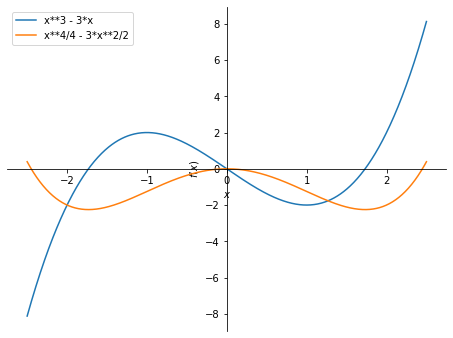

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I = integrate(t**3 - 3*t, (t, 0, x))
plot(x**3 - 3*x, I, (x, -2.5, 2.5), legend=True);
```

</details>